# Topic 17: Chi-square and Categorical Data Analysis
**BIT 4131 Statistical Computing and Reporting | Group work**

| | Question | Test |
|---|---|---|
| A | Is class attendance related to where a student lives? | Chi-square test of independence (3×3) |
| B | Are female and male students equally likely to use the library? | 2×2 chi-square, Yates, Fisher's exact, odds ratio |
| C | Does our sample match the housing office's 40/35/25% split? | Goodness-of-fit |

> **How to run:** click **Run All** at the top. Every table and graph appears right under the cell that makes it.

In [1]:
# Setup: libraries and paths
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as st
from statsmodels.stats.contingency_tables import Table, Table2x2
from pathlib import Path
from IPython.display import display, Markdown
import warnings
warnings.filterwarnings("ignore")
%matplotlib inline

pd.set_option("display.float_format", lambda v: f"{v:.2e}" if 0 < abs(v) < 1e-4 else f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 110})
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"

# find the project folder whether the notebook runs from python/ or the root
ROOT = Path.cwd().parent if (Path.cwd().parent / "data").exists() else Path.cwd()
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)
print("Project folder:", ROOT)

Project folder: c:\xampp\htdocs\chi-square


## 1. Worked example by hand: breakfast and passing the CAT (n = 50)

$$E_{ij} = \frac{R_i\,C_j}{n}, \qquad \chi^2 = \sum \frac{(O_{ij}-E_{ij})^2}{E_{ij}}, \qquad df = (r-1)(c-1)$$

In [2]:
obs = pd.DataFrame([[18, 7], [10, 15]], index=["Ate breakfast", "Skipped breakfast"], columns=["Passed", "Failed"])
display(Markdown("**Observed counts**")); display(obs)

n_w = obs.values.sum()
exp_w = pd.DataFrame(np.outer(obs.sum(1), obs.sum(0)) / n_w, index=obs.index, columns=obs.columns)
display(Markdown("**Expected counts** = row total × column total / n")); display(exp_w)

contrib = (obs - exp_w) ** 2 / exp_w
display(Markdown("**Each cell's contribution** (O − E)² / E")); display(contrib.round(4))

chi_w = contrib.values.sum()
p_w = st.chi2.sf(chi_w, 1)
display(pd.DataFrame({"Value": [chi_w, 1, st.chi2.ppf(0.95, 1), p_w, (18*15)/(7*10)]},
                     index=["Chi-square", "df", "Critical value (5%)", "p-value", "Odds ratio"]))
display(Markdown(f"Since {chi_w:.3f} > 3.841, **reject H₀**: passing is related to eating breakfast (p = {p_w:.4f})."))

**Observed counts**

,Passed,Failed
Ate breakfast,18,7
Skipped breakfast,10,15


**Expected counts** = row total × column total / n

,Passed,Failed
Ate breakfast,14.0000,11.0000
Skipped breakfast,14.0000,11.0000


**Each cell's contribution** (O − E)² / E

,Passed,Failed
Ate breakfast,1.1429,1.4545
Skipped breakfast,1.1429,1.4545


,Value
Chi-square,5.1948
df,1.0000
Critical value (5%),3.8415
p-value,0.0227
Odds ratio,3.8571


Since 5.195 > 3.841, **reject H₀**: passing is related to eating breakfast (p = 0.0227).

## 2. The dataset

In [3]:
df = pd.read_csv(ROOT / "data" / "student_survey.csv")
print(f"{len(df)} students, {df.shape[1]} columns")
display(df.head(10))

res_order = ["Hostel", "Off-campus", "Home"]
att_order = ["High", "Medium", "Low"]

300 students, 6 columns


,student_id,gender,year_of_study,residence,attendance,uses_library
0,S001,Male,1,Off-campus,Medium,Yes
1,S002,Male,3,Home,High,No
2,S003,Female,2,Home,Low,No
3,S004,Female,4,Hostel,Medium,No
4,S005,Female,4,Hostel,Medium,No
5,S006,Female,4,Home,Medium,Yes
6,S007,Female,1,Hostel,High,Yes
7,S008,Female,1,Home,Medium,No
8,S009,Male,2,Home,High,Yes
9,S010,Female,4,Off-campus,Low,Yes


## 3. Question A: is attendance related to residence?

In [4]:
observed = pd.crosstab(df.residence, df.attendance).loc[res_order, att_order]
display(Markdown("**Observed counts (with totals)**"))
display(pd.crosstab(df.residence, df.attendance, margins=True, margins_name="Total")
        .loc[res_order + ["Total"], att_order + ["Total"]])

row_pct = pd.crosstab(df.residence, df.attendance, normalize="index").loc[res_order, att_order] * 100
display(Markdown("**Row percentages**")); display(row_pct.round(1))

**Observed counts (with totals)**

attendance,High,Medium,Low,Total
residence,,,,
Hostel,58,34,13,105
Off-campus,40,46,25,111
Home,18,37,29,84
Total,116,117,67,300


**Row percentages**

attendance,High,Medium,Low
residence,,,
Hostel,55.2000,32.4000,12.4000
Off-campus,36.0000,41.4000,22.5000
Home,21.4000,44.0000,34.5000


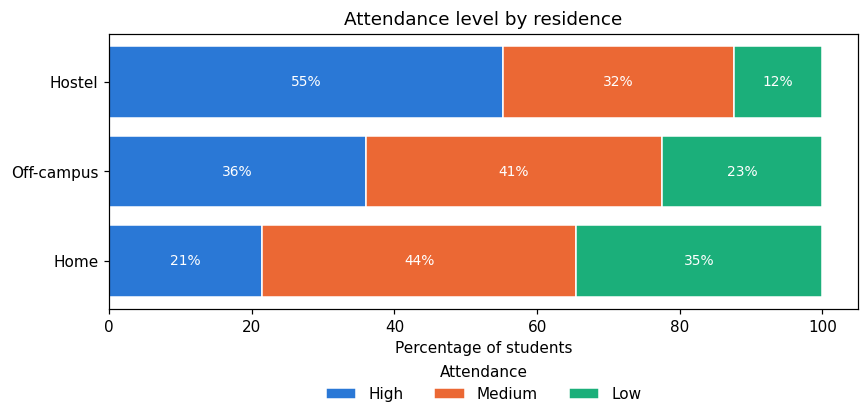

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
left = np.zeros(3)
for col, colour in zip(att_order, [BLUE, ORANGE, AQUA]):
    ax.barh(res_order, row_pct[col], left=left, color=colour, edgecolor="white", label=col)
    for i, v in enumerate(row_pct[col]):
        ax.text(left[i] + v / 2, i, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=9)
    left += row_pct[col].values
ax.invert_yaxis()
ax.set_xlabel("Percentage of students"); ax.set_title("Attendance level by residence")
ax.legend(title="Attendance", frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.15))
fig.tight_layout()
fig.savefig(FIG / "py_01_attendance_by_residence.png", dpi=150)
plt.show()

In [6]:
chi2, p, dof, expected = st.chi2_contingency(observed)
expected = pd.DataFrame(expected, index=res_order, columns=att_order)
display(Markdown("**Expected counts if residence and attendance were independent**"))
display(expected.round(2))

n = observed.values.sum()
cramers_v = np.sqrt(chi2 / (n * (min(observed.shape) - 1)))
display(Markdown("**Chi-square test of independence**"))
display(pd.DataFrame({"Value": [chi2, dof, st.chi2.ppf(0.95, dof), p, cramers_v, expected.values.min()]},
                     index=["Chi-square", "Degrees of freedom", "Critical value (5%)", "p-value",
                            "Cramér's V", "Smallest expected count"]))
display(Markdown(f"**Decision:** {'reject' if p < 0.05 else 'fail to reject'} H₀ at the 5% level."))

**Expected counts if residence and attendance were independent**

,High,Medium,Low
Hostel,40.6000,40.9500,23.4500
Off-campus,42.9200,43.2900,24.7900
Home,32.4800,32.7600,18.7600


**Chi-square test of independence**

,Value
Chi-square,26.2572
Degrees of freedom,4.0000
Critical value (5%),9.4877
p-value,2.81e-05
Cramér's V,0.2092
Smallest expected count,18.7600


**Decision:** reject H₀ at the 5% level.

**Adjusted residuals** (beyond ±1.96 is notable)

,High,Medium,Low
Hostel,4.3200,-1.7200,-3.0400
Off-campus,-0.7200,0.6600,0.0600
Home,-3.8200,1.1200,3.1600


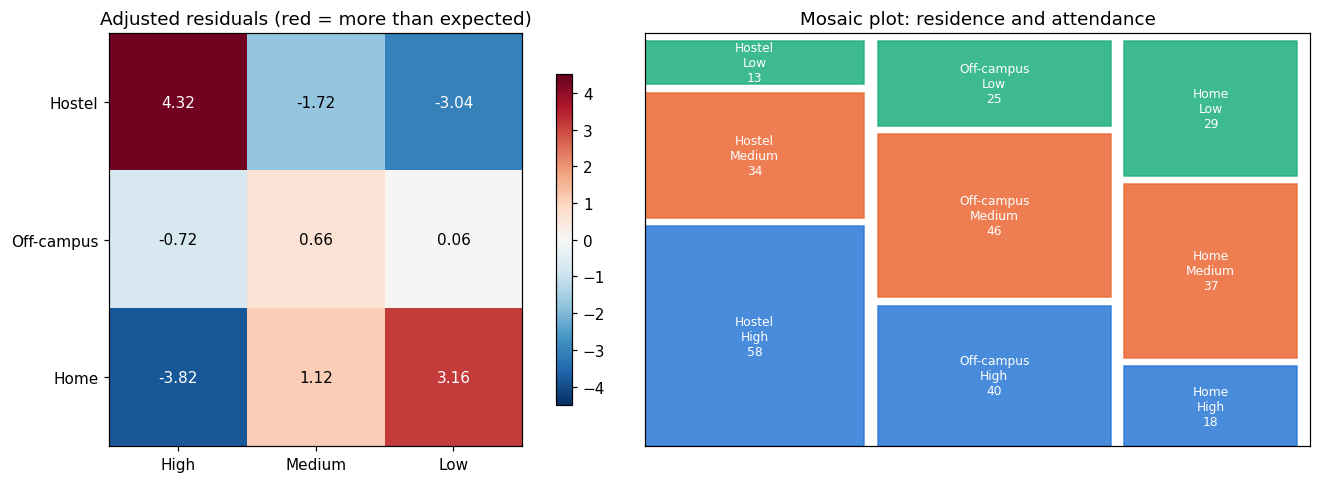

In [7]:
adj = pd.DataFrame(Table(observed).standardized_resids, index=res_order, columns=att_order)
display(Markdown("**Adjusted residuals** (beyond ±1.96 is notable)")); display(adj.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
im = axes[0].imshow(adj.values, cmap="RdBu_r", vmin=-4.5, vmax=4.5)
axes[0].set_xticks(range(3), att_order); axes[0].set_yticks(range(3), res_order)
for i in range(3):
    for j in range(3):
        v = adj.values[i, j]
        axes[0].text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if abs(v) > 2.5 else "black")
axes[0].set_title("Adjusted residuals (red = more than expected)")
fig.colorbar(im, ax=axes[0], shrink=0.8)

# mosaic plot: tile width = share in that residence, height = share at each attendance level
x0 = 0
for rn in res_order:
    row = observed.loc[rn]; w = row.sum() / n; y0 = 0
    for cn, colour in zip(att_order, [BLUE, ORANGE, AQUA]):
        h = row[cn] / row.sum()
        axes[1].add_patch(plt.Rectangle((x0, y0), w - 0.02, h - 0.02, color=colour, alpha=0.85))
        axes[1].text(x0 + (w - 0.02) / 2, y0 + (h - 0.02) / 2, f"{rn}\n{cn}\n{row[cn]}",
                     ha="center", va="center", fontsize=8, color="white")
        y0 += h
    x0 += w
axes[1].set_xlim(0, 1); axes[1].set_ylim(0, 1); axes[1].set_xticks([]); axes[1].set_yticks([])
axes[1].set_title("Mosaic plot: residence and attendance")
fig.tight_layout()
fig.savefig(FIG / "py_02_residuals_and_mosaic.png", dpi=150)
plt.show()

## 4. Question B: gender and library use (2×2)

uses_library,Yes,No,Total,% using
gender,,,,
Female,106,59,165,64.2000
Male,61,74,135,45.2000


,Statistic,p-value,95% CI
Chi-square (no correction),10.9267,0.0009,
Chi-square (Yates),10.1682,0.0014,
Fisher's exact,NaN,0.0011,
Odds ratio (F vs M),2.1795,NaN,1.369 to 3.470
Phi,0.1908,NaN,


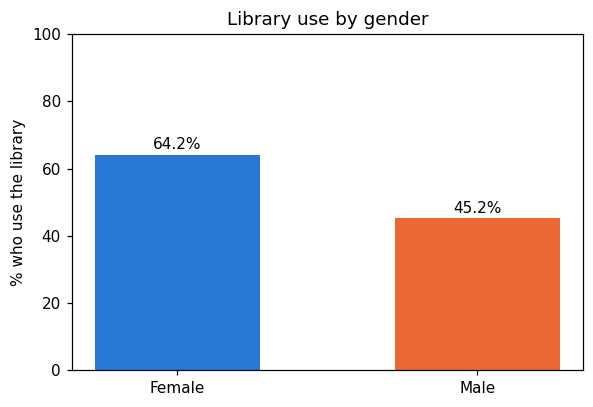

In [8]:
lib = pd.crosstab(df.gender, df.uses_library).loc[["Female", "Male"], ["Yes", "No"]]
show = lib.copy(); show["Total"] = show.sum(1); show["% using"] = (lib["Yes"] / show["Total"] * 100).round(1)
display(show)

chi2_n, p_n, _, _ = st.chi2_contingency(lib, correction=False)
chi2_y, p_y, _, _ = st.chi2_contingency(lib, correction=True)
_, p_f = st.fisher_exact(lib)
t22 = Table2x2(lib.values)
lo, hi = t22.oddsratio_confint()
display(pd.DataFrame({
    "Statistic": [chi2_n, chi2_y, np.nan, t22.oddsratio, np.sqrt(chi2_n / lib.values.sum())],
    "p-value": [p_n, p_y, p_f, np.nan, np.nan],
    "95% CI": ["", "", "", f"{lo:.3f} to {hi:.3f}", ""]},
    index=["Chi-square (no correction)", "Chi-square (Yates)", "Fisher's exact", "Odds ratio (F vs M)", "Phi"]))

fig, ax = plt.subplots(figsize=(5.5, 3.8))
ax.bar(["Female", "Male"], show["% using"], color=[BLUE, ORANGE], width=0.55)
for i, v in enumerate(show["% using"]):
    ax.text(i, v + 1.5, f"{v:.1f}%", ha="center")
ax.set_ylim(0, 100); ax.set_ylabel("% who use the library"); ax.set_title("Library use by gender")
fig.tight_layout()
fig.savefig(FIG / "py_03_library_by_gender.png", dpi=150)
plt.show()

## 5. Question C: goodness-of-fit against the housing office

,Claimed,Observed,Expected,(O − E)² / E
Hostel,0.4000,105,120.0000,1.8750
Off-campus,0.3500,111,105.0000,0.3429
Home,0.2500,84,75.0000,1.0800


χ² = **3.2979**, df = 2, p = **0.1923** → fail to reject H₀

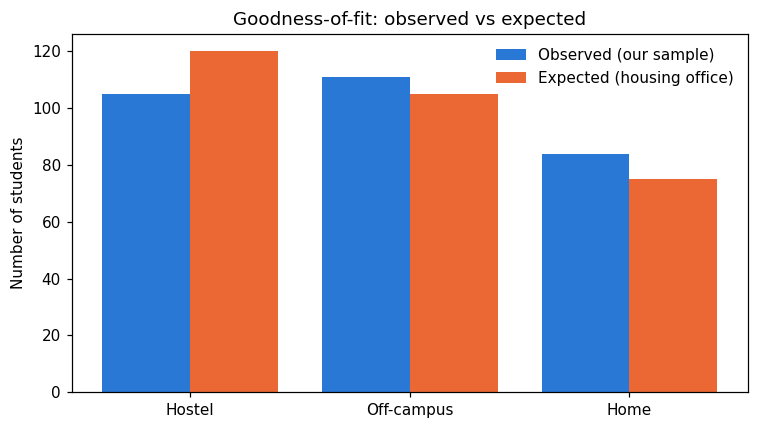

In [9]:
obs_res = df.residence.value_counts().loc[res_order].values
claimed = np.array([0.40, 0.35, 0.25])
exp_res = claimed * obs_res.sum()
gof = st.chisquare(obs_res, f_exp=exp_res)

display(pd.DataFrame({"Claimed": claimed, "Observed": obs_res, "Expected": exp_res,
                      "(O − E)² / E": (obs_res - exp_res) ** 2 / exp_res}, index=res_order))
display(Markdown(f"χ² = **{gof.statistic:.4f}**, df = 2, p = **{gof.pvalue:.4f}** → "
                 f"{'reject' if gof.pvalue < 0.05 else 'fail to reject'} H₀"))

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(3)
ax.bar(x - 0.2, obs_res, width=0.4, color=BLUE, label="Observed (our sample)")
ax.bar(x + 0.2, exp_res, width=0.4, color=ORANGE, label="Expected (housing office)")
ax.set_xticks(x, res_order); ax.set_ylabel("Number of students")
ax.set_title("Goodness-of-fit: observed vs expected"); ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "py_04_goodness_of_fit.png", dpi=150)
plt.show()

## 6. Interpretation

In [10]:
display(Markdown(f"""
**A. Residence and attendance are related.** χ² = {chi2:.2f} on {dof} df, p = {p:.6f}. Cramér's V = {cramers_v:.2f} (medium).
Hostel students have far more high attendance than expected (residual {adj.loc['Hostel','High']:+.2f}),
and students living at home far more low attendance ({adj.loc['Home','Low']:+.2f}).

**B. Female students are more likely to use the library.** {show.loc['Female','% using']}% vs {show.loc['Male','% using']}%.
Fisher p = {p_f:.4f}; odds ratio = {t22.oddsratio:.2f} (95% CI {lo:.2f} to {hi:.2f}).

**C. Our sample matches the housing office's split.** χ² = {gof.statistic:.2f}, p = {gof.pvalue:.2f}, so the sample looks representative.

*Remember: chi-square shows association, not cause.*
"""))


**A. Residence and attendance are related.** χ² = 26.26 on 4 df, p = 0.000028. Cramér's V = 0.21 (medium).
Hostel students have far more high attendance than expected (residual +4.32),
and students living at home far more low attendance (+3.16).

**B. Female students are more likely to use the library.** 64.2% vs 45.2%.
Fisher p = 0.0011; odds ratio = 2.18 (95% CI 1.37 to 3.47).

**C. Our sample matches the housing office's split.** χ² = 3.30, p = 0.19, so the sample looks representative.

*Remember: chi-square shows association, not cause.*
